# 09 · F_05 SE003 Train04：完整标注0–35秒的疑似误报核查

用户明确确认0–35秒已完整标注，已将该覆盖范围存入reviewed_intervals.csv；不是程序自行推断正常区间。只在此范围内对照。眨眼候选仍不自动拒绝epoch，检测参数不变。

10–35秒：12段人工疑似眨眼均有相交候选；15个自动候选中3个未匹配。相对人工参考的候选匹配比例为12/15=80%，未匹配比例为20%；**20%不是样本级假阳性率**。事件级人工覆盖为12/12，只反映这一已复核训练区间，不能推广到全文件或其他被试。匹配采用任意正时长相交，并非严格边界准确。

0–10秒另有1个未匹配候选，属于启动保护区，单独展示，不混入上述统计。无候选跨越35秒边界，也没有本区间候选需要等到35秒以后才能判定。


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/expanded_pilot.json').exists())
OUT=ROOT/'outputs/blink_annotation_update/reviewed_0_35'
t=pd.read_csv(OUT/'reviewed_candidates.csv')
display(t)
display(pd.read_csv(OUT/'suspected_false_positive_candidates.csv'))

,blink_candidate_id,onset_seconds,peak_seconds,offset_seconds,decision_seconds,startup,fully_within_review,decision_by_review_end,matched_manual_ids,unmatched_to_complete_annotation,frontal_amplitude_uv,posterior_amplitude_uv,frontal_posterior_metric
0,F_05_SE003_CBCol_Train04_B0001,0.902344,0.941406,1.339844,1.492188,True,True,True,F_05_SE003_CBCol_Train04_M0001,False,45.895809,5.185130,8.851428
1,F_05_SE003_CBCol_Train04_B0002,1.800781,1.855469,2.132812,2.285156,True,True,True,F_05_SE003_CBCol_Train04_M0002,False,54.574839,19.056927,2.863780
2,F_05_SE003_CBCol_Train04_B0003,2.437500,2.507812,3.097656,3.250000,True,True,True,F_05_SE003_CBCol_Train04_M0003,False,62.495792,3.041874,20.545158
3,F_05_SE003_CBCol_Train04_B0004,3.582031,3.625000,4.296875,4.449219,True,True,True,NaN,True,25.781811,9.917727,2.599569
4,F_05_SE003_CBCol_Train04_B0005,6.707031,6.964844,7.195312,7.347656,True,True,True,F_05_SE003_CBCol_Train04_M0004,False,54.635833,2.912846,18.756853
5,F_05_SE003_CBCol_Train04_B0006,7.417969,7.738281,8.128906,8.281250,True,True,True,F_05_SE003_CBCol_Train04_M0005,False,62.598859,2.616323,23.926273
6,F_05_SE003_CBCol_Train04_B0007,8.660156,8.730469,9.148438,9.300781,True,True,True,F_05_SE003_CBCol_Train04_M0006,False,55.071578,2.128826,25.869455
7,F_05_SE003_CBCol_Train04_B0008,11.328125,11.382812,11.734375,11.886719,False,True,True,F_05_SE003_CBCol_Train04_M0007,False,52.702614,4.653817,11.324600
8,F_05_SE003_CBCol_Train04_B0009,13.574219,13.832031,14.035156,14.187500,False,True,True,F_05_SE003_CBCol_Train04_M0008,False,56.616359,2.487545,22.759938
9,F_05_SE003_CBCol_Train04_B0010,14.250000,14.371094,14.621094,14.773438,False,True,True,NaN,True,27.076160,2.059396,13.147619


,blink_candidate_id,onset_seconds,peak_seconds,offset_seconds,decision_seconds,startup,fully_within_review,decision_by_review_end,matched_manual_ids,unmatched_to_complete_annotation,frontal_amplitude_uv,posterior_amplitude_uv,frontal_posterior_metric
0,F_05_SE003_CBCol_Train04_B0004,3.582031,3.625000,4.296875,4.449219,True,True,True,NaN,True,25.781811,9.917727,2.599569
1,F_05_SE003_CBCol_Train04_B0010,14.250000,14.371094,14.621094,14.773438,False,True,True,NaN,True,27.076160,2.059396,13.147619
2,F_05_SE003_CBCol_Train04_B0014,21.886719,22.105469,22.316406,22.468750,False,True,True,NaN,True,49.832233,2.849589,17.487518
3,F_05_SE003_CBCol_Train04_B0020,30.433594,30.667969,30.808594,30.960938,False,True,True,NaN,True,27.467875,2.286747,12.011769


## 未匹配片段波形

每图四行依次为原始额区、正式分析额区、正式分析后部、辅助慢分支。绿色=人工标注，橙色=自动候选，红虚线=此未匹配候选的峰，紫点线=其判定时间，灰竖线=flash。

这些是相对于完整人工标注的**疑似误报**，仍应复核是否是眨眼后的反向恢复波被拆成第二个候选、其他共同额区变化，或人工边界太窄。辅助因果分支增加的延迟可能造成边界错位；不能仅靠未相交就断定具体原因。


### 3.582–4.297秒（启动期，单独报告）

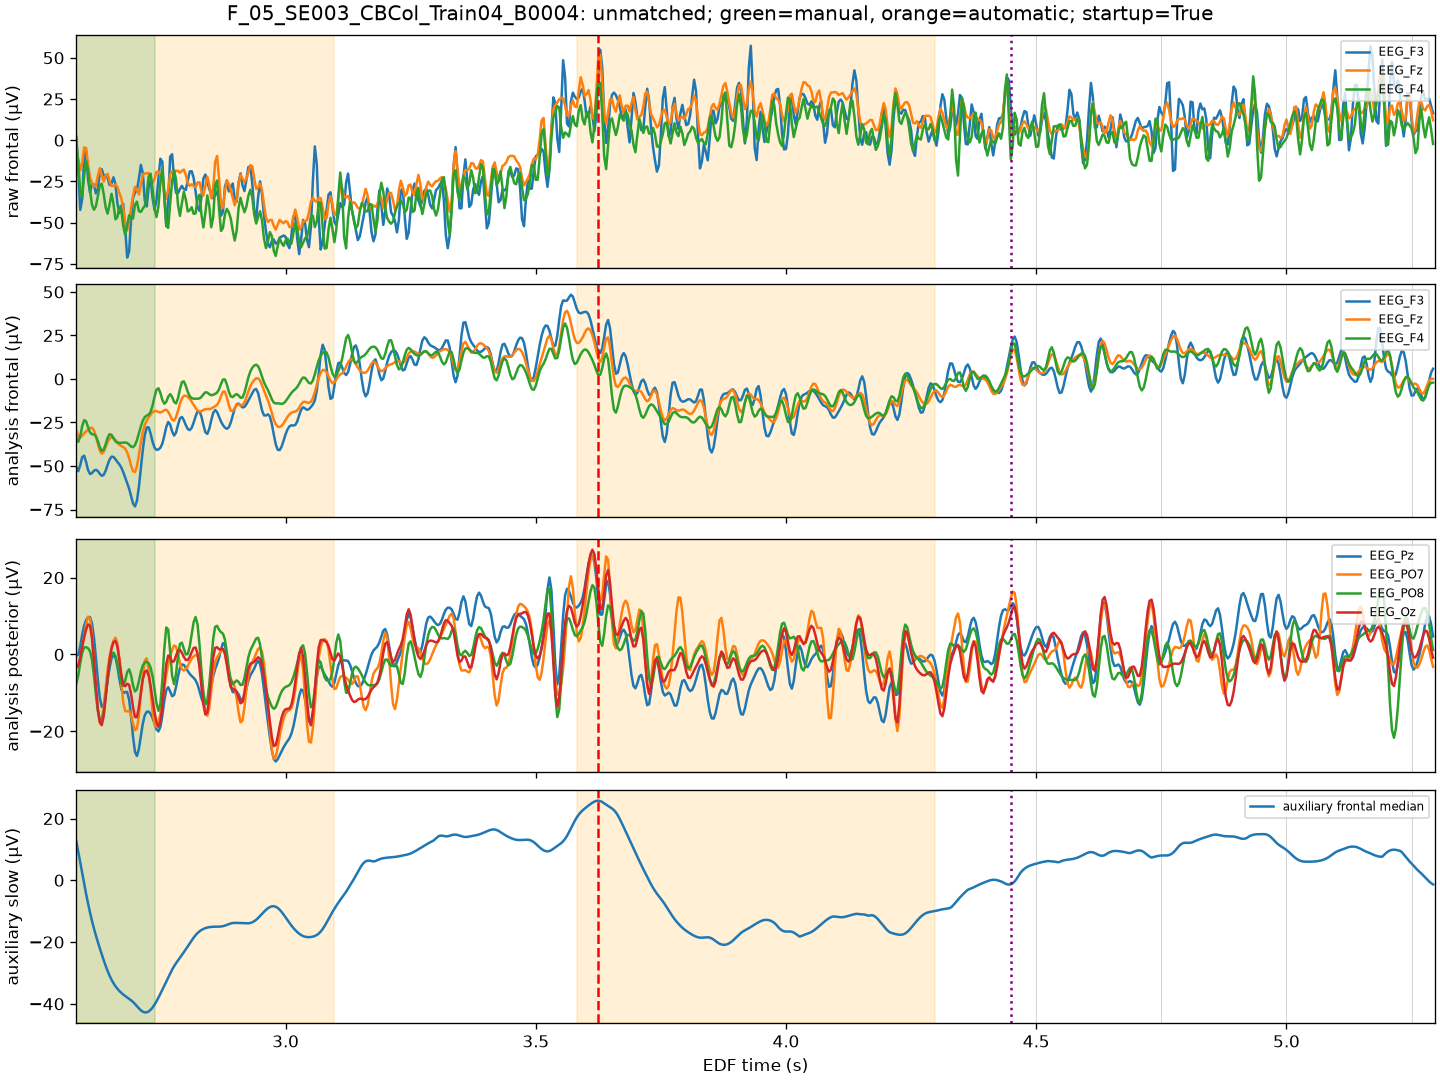

In [2]:
display(Image(filename=str(OUT/'F_05_SE003_CBCol_Train04_B0004.png'),width=1100))

### 14.250–14.621秒

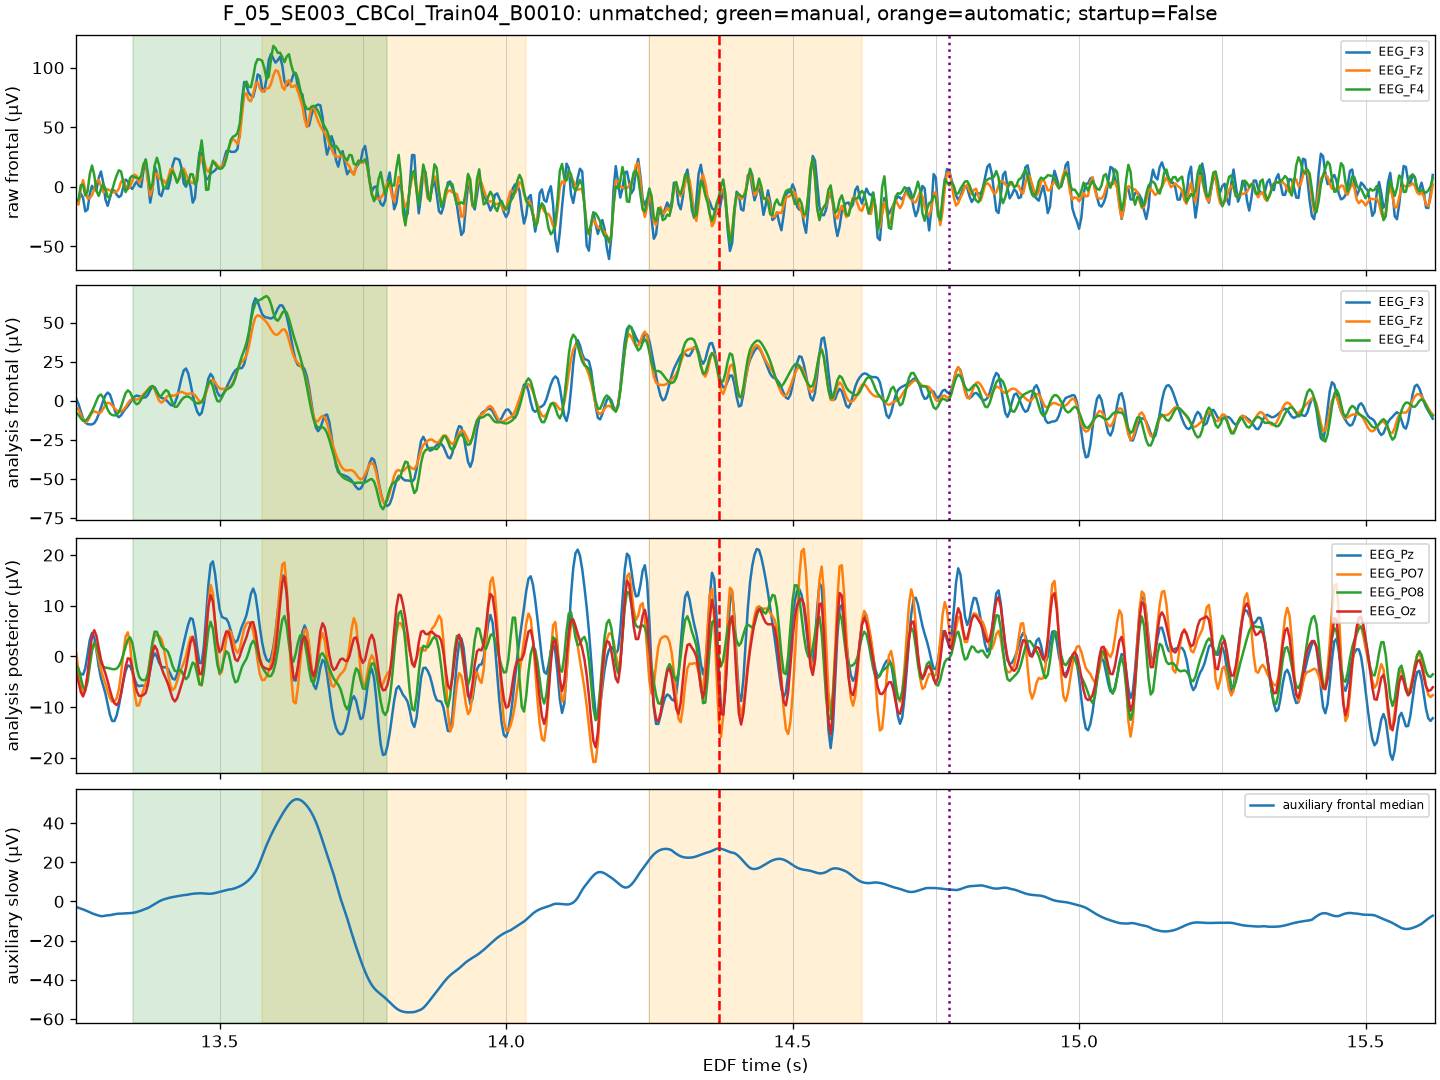

In [3]:
display(Image(filename=str(OUT/'F_05_SE003_CBCol_Train04_B0010.png'),width=1100))

### 21.887–22.316秒

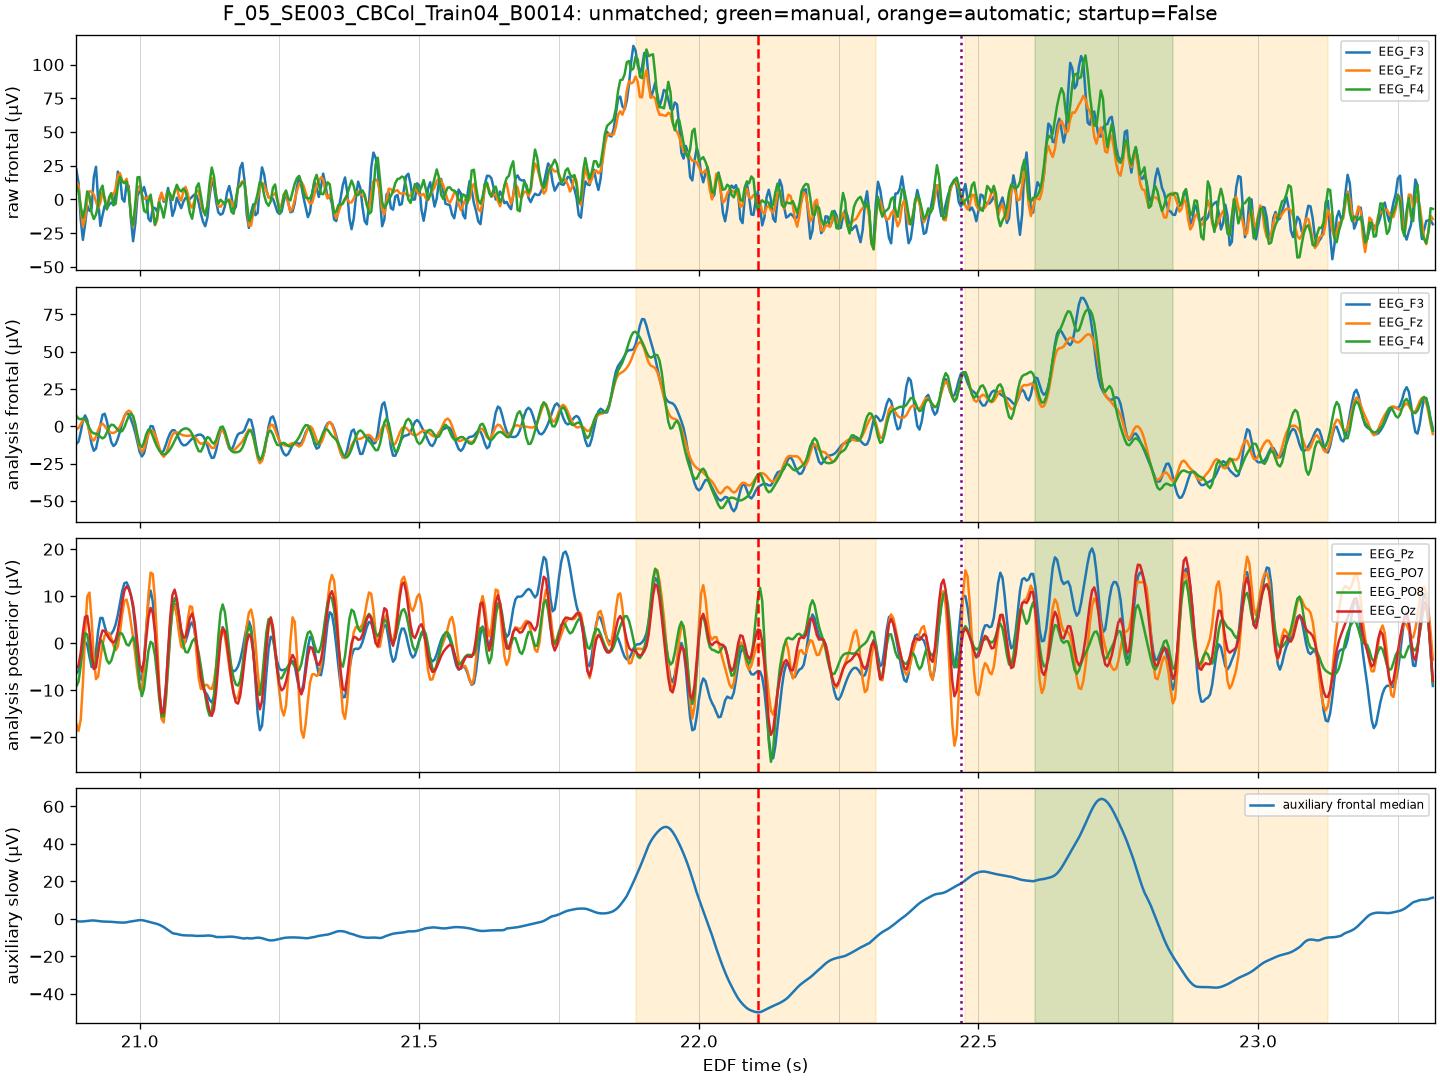

In [4]:
display(Image(filename=str(OUT/'F_05_SE003_CBCol_Train04_B0014.png'),width=1100))

### 30.434–30.809秒

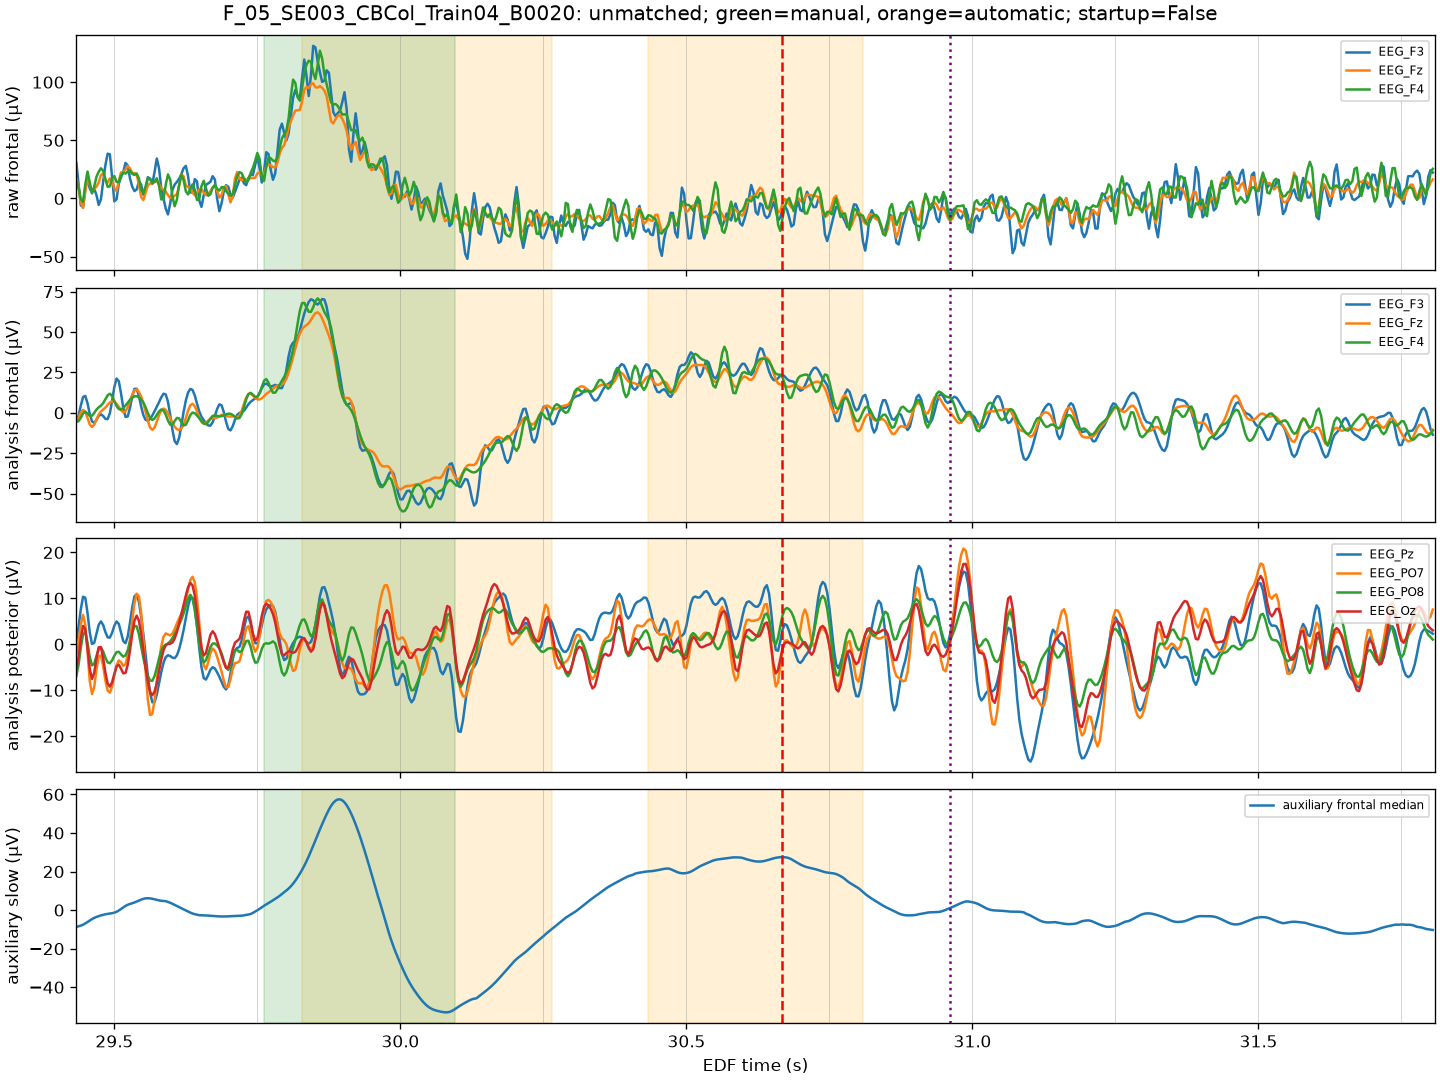

In [5]:
display(Image(filename=str(OUT/'F_05_SE003_CBCol_Train04_B0020.png'),width=1100))

## 当前判断

存在未匹配候选，说明“覆盖已标眨眼很多”不代表没有误报。先针对这3段复核波形，再决定是否需要调整恢复、合并或慢波形态条件；不直接降低幅值阈值，也不为这35秒单独调出最优参数。其他未完整复核的区间仍属于未知。

重新计算并画图：`scripts/inspect_reviewed_blinks.py`。最新全文件人工对照：notebook08。